#**Load Dataset**

In [ ]:
!pip install --upgrade pip

!pip install statsmodels pmdarima
import warnings

# Ignore Warnings
warnings.filterwarnings("ignore")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 27.5 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 47.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error

import kagglehub

# Download latest version
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")

import os

# Lihat isi folder hasil download
files = os.listdir(path)
print("Files in dataset directory:", files)

csv_path = os.path.join(path, "Microsoft_Stock.csv")
df = pd.read_csv(csv_path)

100%|██████████| 26.7k/26.7k [00:00<00:00, 31.0MB/s]

Extracting files...
Files in dataset directory: ['Microsoft_Stock.csv']


In [ ]:
# Display dataset info and description
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1511 entries, 0 to 1510
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1511 non-null   object 
 1   Open    1511 non-null   float64
 2   High    1511 non-null   float64
 3   Low     1511 non-null   float64
 4   Close   1511 non-null   float64
 5   Volume  1511 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 71.0+ KB
None
              Open         High          Low        Close        Volume
count  1511.000000  1511.000000  1511.000000  1511.000000  1.511000e+03
mean    107.385976   108.437472   106.294533   107.422091  3.019863e+07
std      56.691333    57.382276    55.977155    56.702299  1.425266e+07
min      40.340000    40.740000    39.720000    40.290000  1.016120e+05
25%      57.860000    58.060000    57.420000    57.855000  2.136213e+07
50%      93.990000    95.100000    92.920000    93.860000  2.662962e+07
75%     139.440000   140.3

In [ ]:
df.head()

,Date,Open,High,Low,Close,Volume
0,4/1/2015 16:00:00,40.60,40.76,40.31,40.72,36865322
1,4/2/2015 16:00:00,40.66,40.74,40.12,40.29,37487476
2,4/6/2015 16:00:00,40.34,41.78,40.18,41.55,39223692
3,4/7/2015 16:00:00,41.61,41.91,41.31,41.53,28809375
4,4/8/2015 16:00:00,41.48,41.69,41.04,41.42,24753438


#**EDA**

Descriptive Statistics:
              Open         High          Low        Close        Volume
count  1511.000000  1511.000000  1511.000000  1511.000000  1.511000e+03
mean    107.385976   108.437472   106.294533   107.422091  3.019863e+07
std      56.691333    57.382276    55.977155    56.702299  1.425266e+07
min      40.340000    40.740000    39.720000    40.290000  1.016120e+05
25%      57.860000    58.060000    57.420000    57.855000  2.136213e+07
50%      93.990000    95.100000    92.920000    93.860000  2.662962e+07
75%     139.440000   140.325000   137.825000   138.965000  3.431962e+07
max     245.030000   246.130000   242.920000   244.990000  1.352271e+08


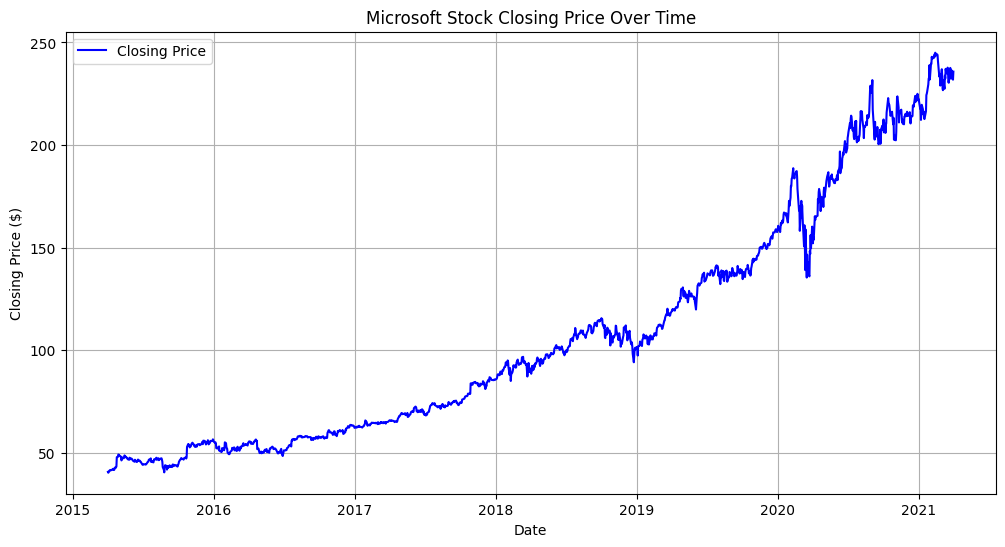

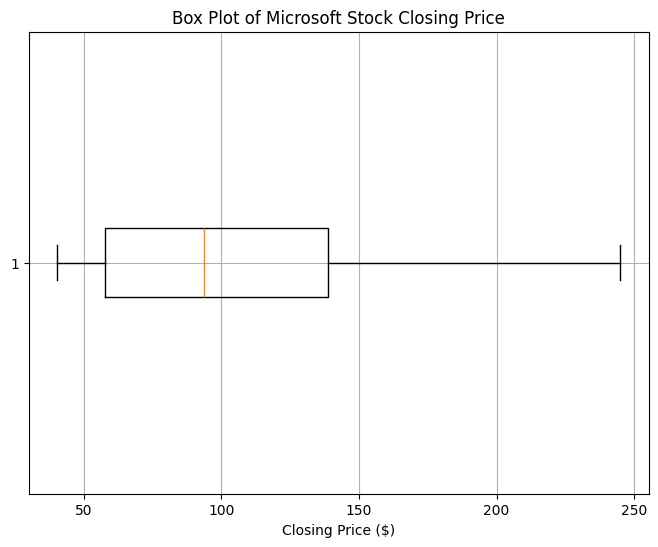

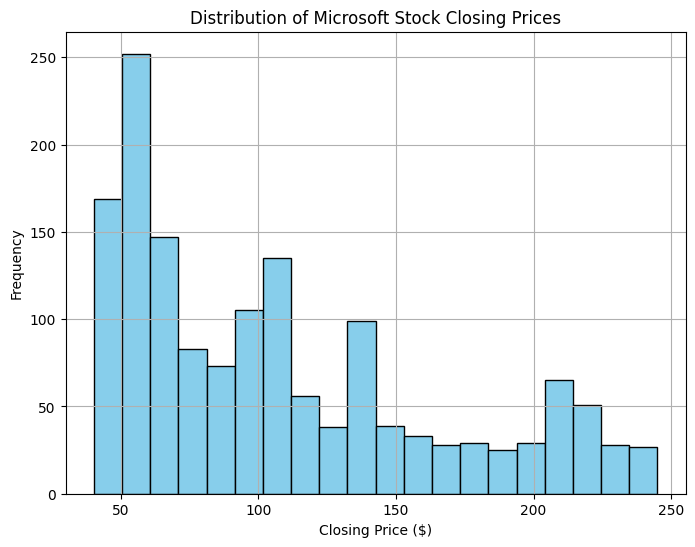

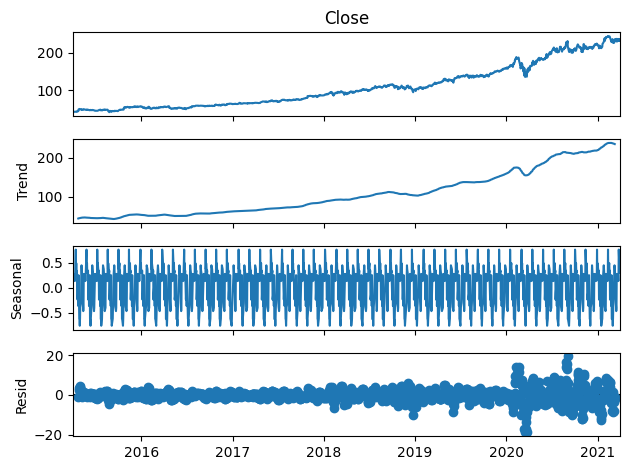

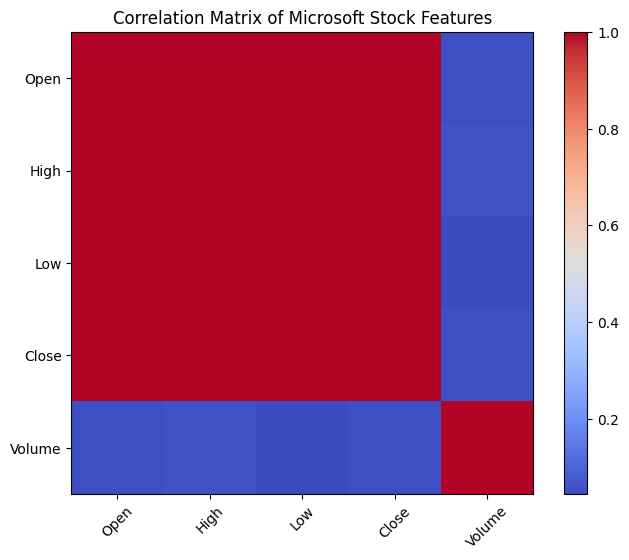

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load data (assuming the data is already in the dataframe 'df')
# If the data is in a CSV or another source, you'd use df = pd.read_csv() or similar.

# Ensure the 'Date' column is converted to datetime
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# Descriptive statistics
print("Descriptive Statistics:")
print(df.describe())

# Line plot to visualize the trend of Closing Price over time
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label='Closing Price', color='blue')
plt.title('Microsoft Stock Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price ($)')
plt.legend()
plt.grid(True)
plt.show()

# Boxplot to check for outliers in the Closing Price
plt.figure(figsize=(8, 6))
plt.boxplot(df['Close'], vert=False)
plt.title('Box Plot of Microsoft Stock Closing Price')
plt.xlabel('Closing Price ($)')
plt.grid(True)
plt.show()

# Histogram of Closing Price distribution
plt.figure(figsize=(8, 6))
plt.hist(df['Close'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Microsoft Stock Closing Prices')
plt.xlabel('Closing Price ($)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Decompose the time series (using the 'Close' column to analyze trends, seasonality, and noise)
result = seasonal_decompose(df['Close'], model='additive', period=30)  # Adjust period based on data frequency (e.g., daily data has 30-day seasonality)
result.plot()
plt.show()

# Visualizing the correlation between the features (Open, High, Low, Close, and Volume)
plt.figure(figsize=(8, 6))
correlation_matrix = df[['Open', 'High', 'Low', 'Close', 'Volume']].corr()
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.title('Correlation Matrix of Microsoft Stock Features')
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.show()

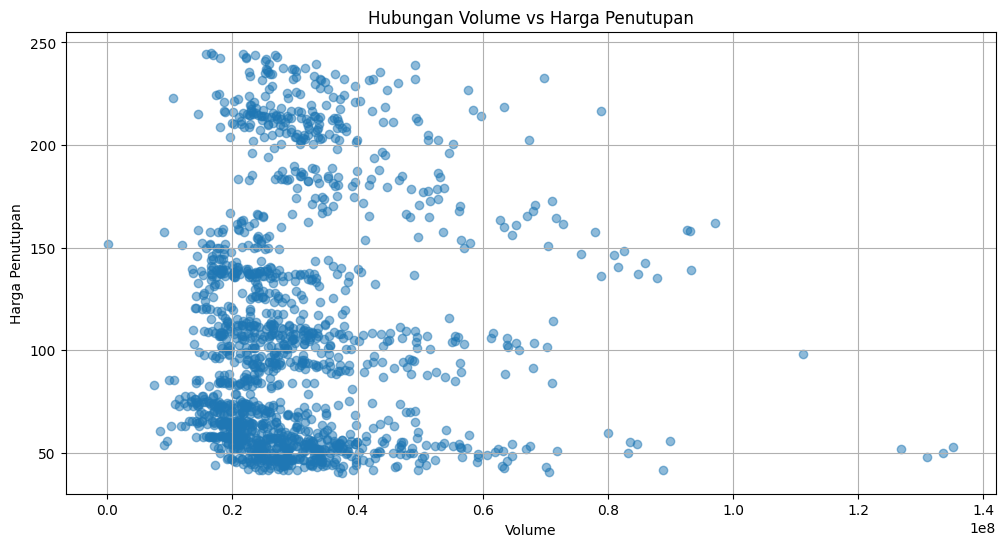

In [ ]:
# Plot hubungan antara volume dan harga penutupan
plt.figure(figsize=(12, 6))
plt.scatter(df['Volume'], df['Close'], alpha=0.5)
plt.title('Hubungan Volume vs Harga Penutupan')
plt.xlabel('Volume')
plt.ylabel('Harga Penutupan')
plt.grid(True)
plt.show()

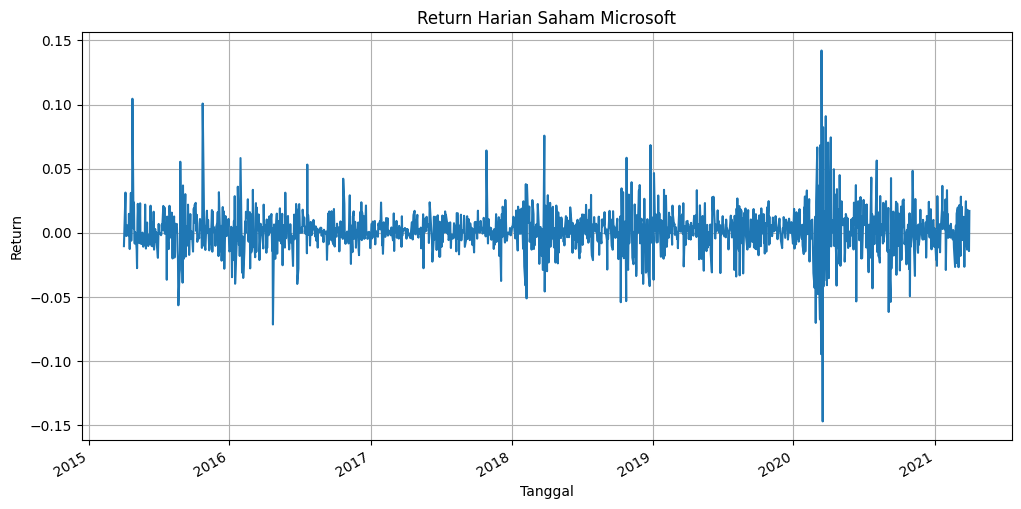

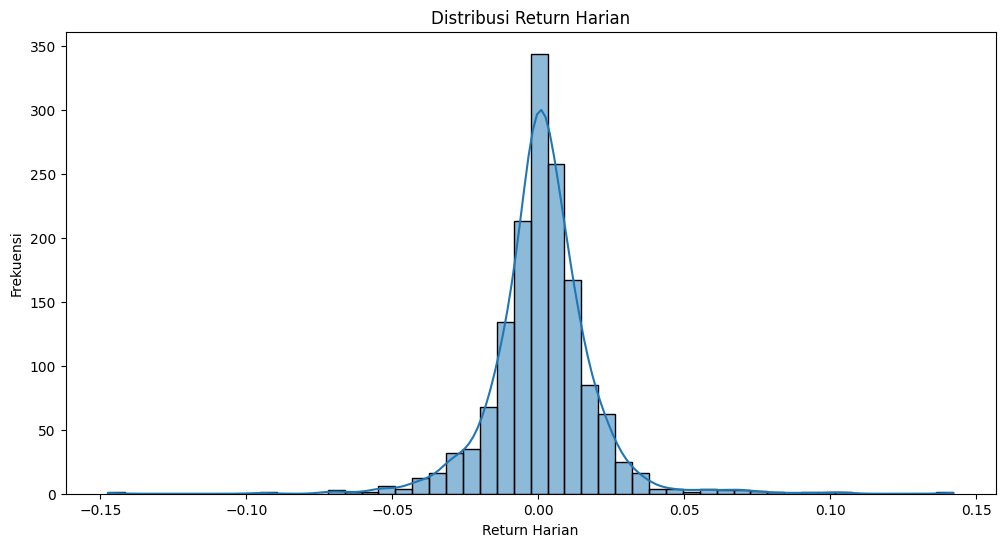

In [ ]:
import seaborn as sns

# Hitung return harian
df['Daily_Return'] = df['Close'].pct_change()

# Plot return harian
plt.figure(figsize=(12, 6))
df['Daily_Return'].plot()
plt.title('Return Harian Saham Microsoft')
plt.xlabel('Tanggal')
plt.ylabel('Return')
plt.grid(True)
plt.show()

# Distribusi return harian
plt.figure(figsize=(12, 6))
sns.histplot(df['Daily_Return'].dropna(), bins=50, kde=True)
plt.title('Distribusi Return Harian')
plt.xlabel('Return Harian')
plt.ylabel('Frekuensi')
plt.show()

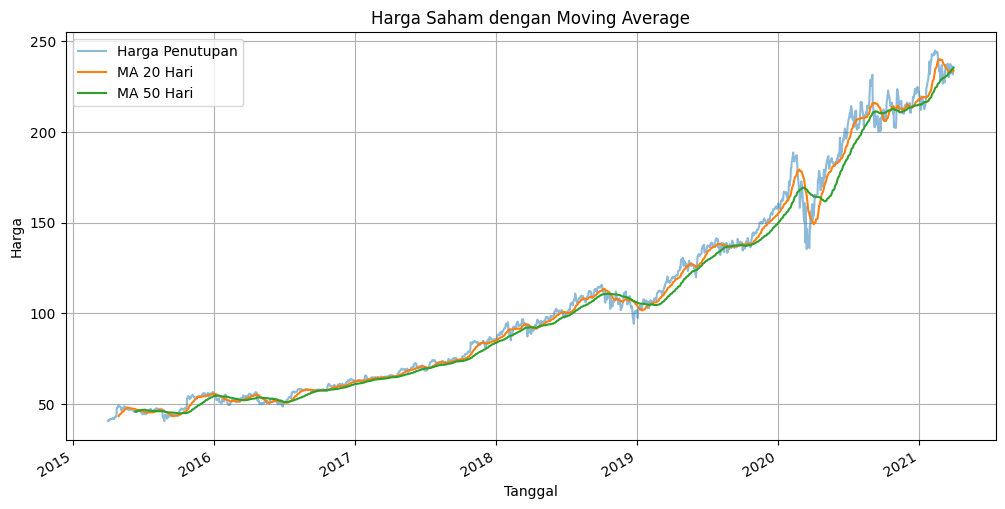

In [ ]:
# Hitung moving average 20 dan 50 hari
df['MA_20'] = df['Close'].rolling(window=20).mean()
df['MA_50'] = df['Close'].rolling(window=50).mean()

# Plot harga penutupan dengan moving average
plt.figure(figsize=(12, 6))
df['Close'].plot(label='Harga Penutupan', alpha=0.5)
df['MA_20'].plot(label='MA 20 Hari')
df['MA_50'].plot(label='MA 50 Hari')
plt.title('Harga Saham dengan Moving Average')
plt.xlabel('Tanggal')
plt.ylabel('Harga')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(df.isnull().sum())

Open             0
High             0
Low              0
Close            0
Volume           0
Daily_Return     1
MA_20           19
MA_50           49
dtype: int64


#**Decompose the series**

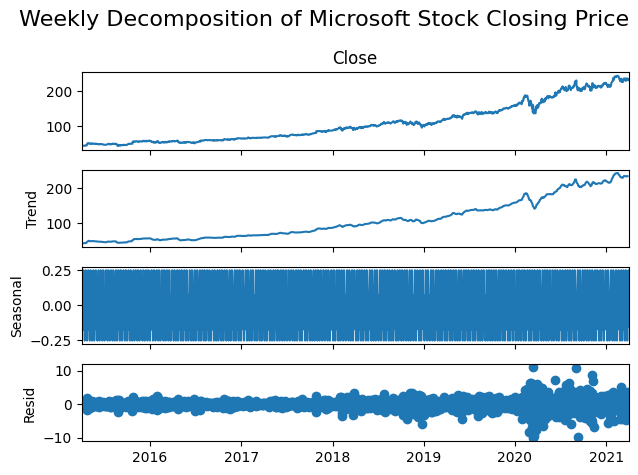

In [ ]:
# Perform decomposition with weekly period (7 days)
decomposition = seasonal_decompose(df['Close'], model='additive', period=7)

# Plot the decomposition with a custom title
fig = decomposition.plot()
fig.suptitle('Weekly Decomposition of Microsoft Stock Closing Price', fontsize=16)
plt.tight_layout()  # Adjust layout to avoid overlap
plt.show()


#**Check for Stationarity**

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform Augmented Dickey-Fuller test on 'Close' (Microsoft stock closing price)
result = adfuller(df['Close'])

# Print the ADF Statistic and p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

# Check if the data is stationary
if result[1] <= 0.05:
    print("Data is stationary.")
else:
    print("Data is not stationary.")

ADF Statistic: 1.7371362899270968
p-value: 0.9982158366942122
Data is not stationary.


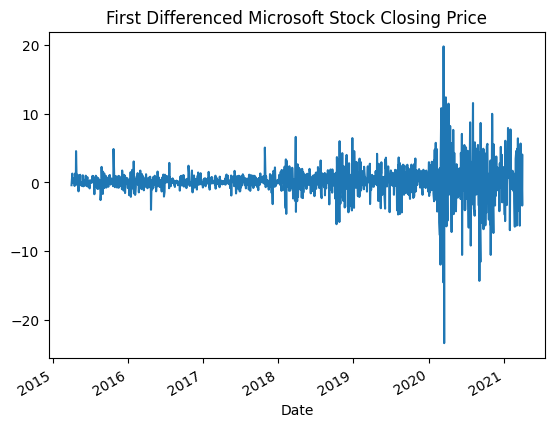

In [ ]:
# First differencing on 'Close' (Microsoft stock closing price)
df['Close_diff'] = df['Close'].diff()

# Plot the first differenced series
df['Close_diff'].dropna().plot(title='First Differenced Microsoft Stock Closing Price')
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform Augmented Dickey-Fuller test on the first differenced series of 'Close' (Microsoft stock closing price)
result = adfuller(df['Close_diff'].dropna())

# Print the ADF Statistic and p-value
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')

# Check if the data is stationary
if result[1] <= 0.05:
    print("The first differenced data is stationary.")
else:
    print("The first differenced data is not stationary.")

ADF Statistic: -10.038331065146398
p-value: 1.519593991753183e-17
The first differenced data is stationary.


##**Transformer S1 Baseline**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

In [ ]:
np.random.seed(53)
tf.random.set_seed(53)

In [ ]:
# Download dataset Microsoft stock time series
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")
file_path = os.path.join(path, "Microsoft_Stock.csv")


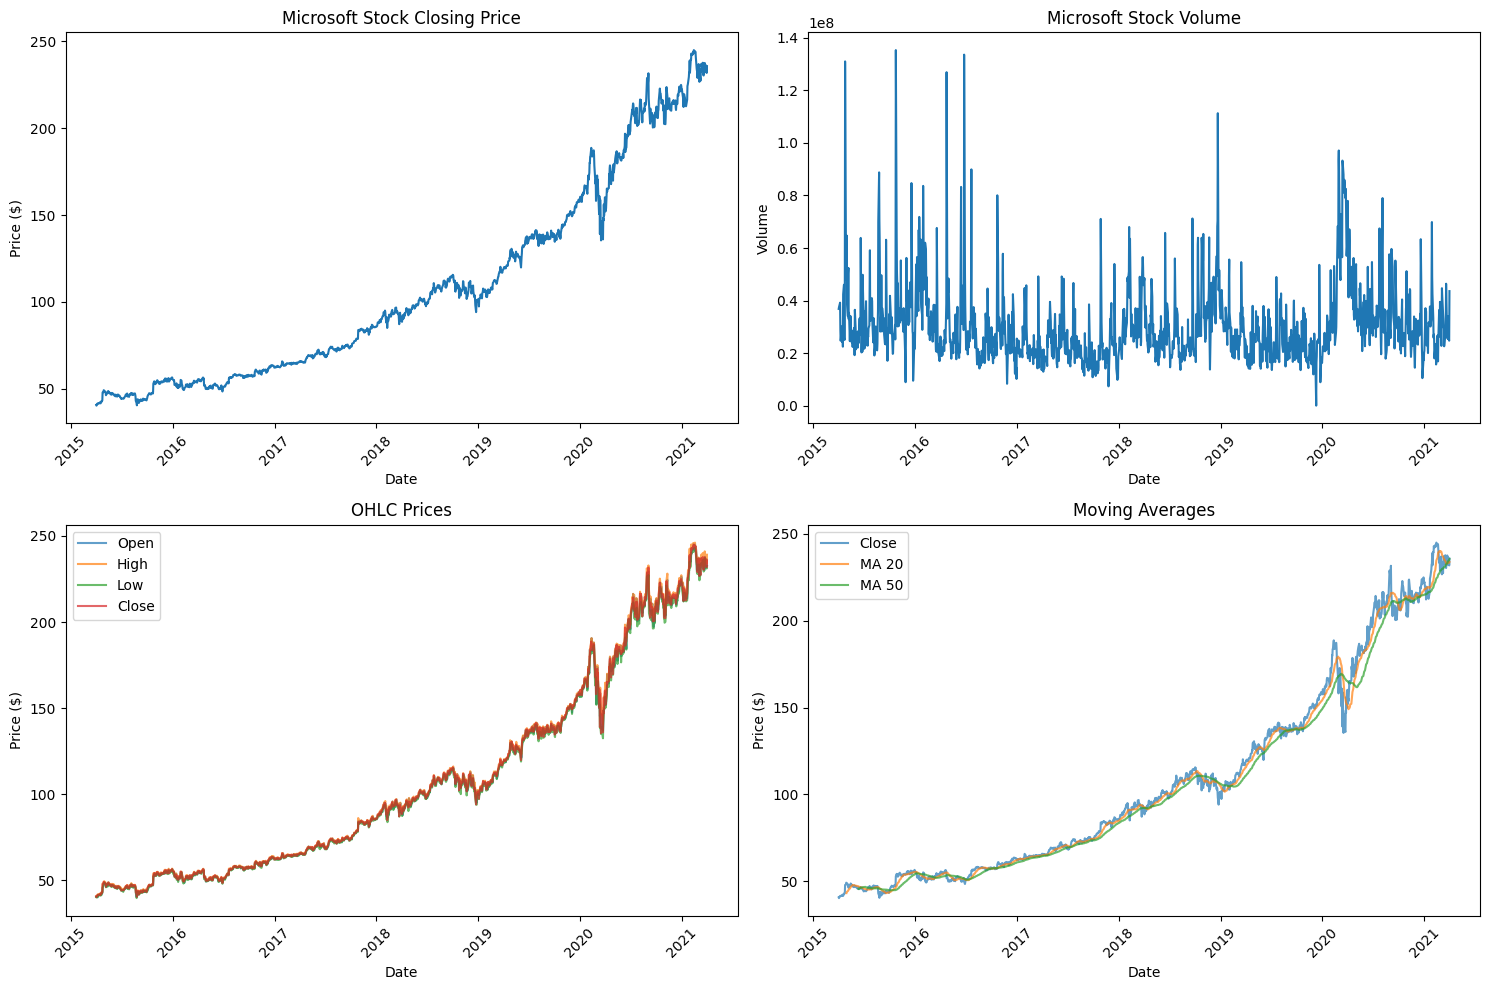

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 60, 64)    │        128 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 64)    │     16,640 │ dense_15[0][0],   │
│ (MultiHeadAttentio… │                   │            │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 60, 64)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 60, 64)    │          0 │ dense_15[0][0],   │
│                     │                   │            │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 64)    │        128 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 60, 64)    │      8,320 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 60, 64)    │          0 │ sequential_3[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 60, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 64)    │        128 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 25)        │      1,625 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 1)         │         26 │ dense_18[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,995 (105.45 KB)

 Trainable params: 26,995 (105.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - loss: 0.2281 - mae: 0.3370 - mse: 0.2281 - val_loss: 0.0331 - val_mae: 0.1754 - val_mse: 0.0331 - learning_rate: 0.0010
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0053 - mae: 0.0565 - mse: 0.0053 - val_loss: 0.0158 - val_mae: 0.1169 - val_mse: 0.0158 - learning_rate: 0.0010
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0029 - mae: 0.0433 - mse: 0.0029 - val_loss: 0.0110 - val_mae: 0.0945 - val_mse: 0.0110 - learning_rate: 0.0010
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0026 - mae: 0.0413 - mse: 0.0026 - val_loss: 0.0119 - val_mae: 0.0996 - val_mse: 0.0119 - learning_rate: 0.0010
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0021 - mae: 0.0358 - mse: 0.0021 - val_loss: 0.0096 - val_mae: 0.0876 - val_mse: 0.0096 - learning_rate: 0.0010
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0022 - mae: 0.0375 - mse: 0.0022 - val_loss: 0.0066 - val_mae: 0.068

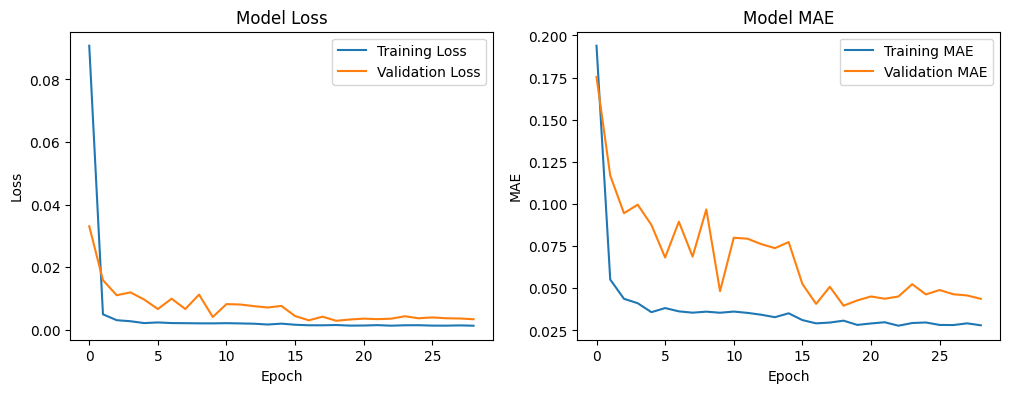

In [ ]:
class TransformerStockPredictor:
    def __init__(self, sequence_length=60, tf_units=50, dropout_rate=0.2):
        self.sequence_length = sequence_length
        self.tf_units = tf_units
        self.dropout_rate = dropout_rate
        self.scaler = MinMaxScaler(feature_range=(0, 1))
        self.model = None

    def load_and_preprocess_data(self, file_path):
        """Load and preprocess the stock data"""
        df = pd.read_csv(file_path)
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.sort_values('Date').reset_index(drop=True)
        return df

    def visualize_data(self, df):
        plt.figure(figsize=(15, 10))

        plt.subplot(2, 2, 1)
        plt.plot(df['Date'], df['Close'])
        plt.title('Microsoft Stock Closing Price')
        plt.xlabel('Date')
        plt.ylabel('Price ($)')
        plt.xticks(rotation=45)

        plt.subplot(2, 2, 2)
        plt.plot(df['Date'], df['Volume'])
        plt.title('Microsoft Stock Volume')
        plt.xlabel('Date')
        plt.ylabel('Volume')
        plt.xticks(rotation=45)

        plt.subplot(2, 2, 3)
        plt.plot(df['Date'], df['Open'], label='Open', alpha=0.7)
        plt.plot(df['Date'], df['High'], label='High', alpha=0.7)
        plt.plot(df['Date'], df['Low'], label='Low', alpha=0.7)
        plt.plot(df['Date'], df['Close'], label='Close', alpha=0.7)
        plt.title('OHLC Prices')
        plt.xlabel('Date')
        plt.ylabel('Price ($)')
        plt.legend()
        plt.xticks(rotation=45)

        plt.subplot(2, 2, 4)
        df['MA_20'] = df['Close'].rolling(window=20).mean()
        df['MA_50'] = df['Close'].rolling(window=50).mean()
        plt.plot(df['Date'], df['Close'], label='Close', alpha=0.7)
        plt.plot(df['Date'], df['MA_20'], label='MA 20', alpha=0.7)
        plt.plot(df['Date'], df['MA_50'], label='MA 50', alpha=0.7)
        plt.title('Moving Averages')
        plt.xlabel('Date')
        plt.ylabel('Price ($)')
        plt.legend()
        plt.xticks(rotation=45)

        plt.tight_layout()
        plt.show()

    def create_sequences(self, data):
        X, y = [], []
        for i in range(self.sequence_length, len(data)):
            X.append(data[i-self.sequence_length:i, 0])
            y.append(data[i, 0])
        return np.array(X), np.array(y)

    def prepare_data(self, df, target_column='Close', train_ratio=0.8):
        data = df[target_column].values.reshape(-1, 1)
        scaled_data = self.scaler.fit_transform(data)
        X, y = self.create_sequences(scaled_data)
        train_size = int(len(X) * train_ratio)
        X_train, X_test = X[:train_size], X[train_size:]
        y_train, y_test = y[:train_size], y[train_size:]
        X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
        X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
        return X_train, X_test, y_train, y_test, scaled_data

    def build_transformer_model(self):
        input_layer = tf.keras.Input(shape=(self.sequence_length, 1))
        x = tf.keras.layers.Dense(64)(input_layer)
        attention_output = tf.keras.layers.MultiHeadAttention(num_heads=2, key_dim=32)(x, x)
        attention_output = tf.keras.layers.Dropout(self.dropout_rate)(attention_output)
        attention_output = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)
        ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(64),
        ])
        ffn_output = ffn(attention_output)
        ffn_output = tf.keras.layers.Dropout(self.dropout_rate)(ffn_output)
        sequence_output = tf.keras.layers.LayerNormalization(epsilon=1e-6)(attention_output + ffn_output)
        x = tf.keras.layers.GlobalAveragePooling1D()(sequence_output)
        x = tf.keras.layers.Dense(25, activation='relu')(x)
        output = tf.keras.layers.Dense(1)(x)
        self.model = tf.keras.Model(inputs=input_layer, outputs=output)
        self.model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss='mse',
            metrics=['mae', 'mse']
        )
        self.model.summary()
        return self.model

    def train_model(self, X_train, y_train, epochs=100, batch_size=32, validation_split=0.1):
        early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)
        history = self.model.fit(
            X_train, y_train,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=validation_split,
            callbacks=[early_stopping, reduce_lr],
            verbose=1
        )
        return history

    def evaluate_model(self, X_test, y_test):
        predictions = self.model.predict(X_test)
        predictions = self.scaler.inverse_transform(predictions)
        y_test_actual = self.scaler.inverse_transform(y_test.reshape(-1, 1))
        mse = mean_squared_error(y_test_actual, predictions)
        mae = mean_absolute_error(y_test_actual, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test_actual, predictions)
        print(f"Model Performance Metrics:\nMSE: {mse:.4f}\nMAE: {mae:.4f}\nRMSE: {rmse:.4f}\nR² Score: {r2:.4f}")
        return predictions, y_test_actual, {'MSE': mse, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

    def plot_training_history(self, history):
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(history.history['loss'], label='Training Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.title('Model Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epoch')
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(history.history['mae'], label='Training MAE')
        plt.plot(history.history['val_mae'], label='Validation MAE')
        plt.title('Model MAE')
        plt.ylabel('MAE')
        plt.xlabel('Epoch')
        plt.legend()
        plt.show()

  # Eksekusi
predictor = TransformerStockPredictor(sequence_length=60)
df = predictor.load_and_preprocess_data(file_path)
predictor.visualize_data(df)
X_train, X_test, y_train, y_test, scaled_data = predictor.prepare_data(df, target_column='Close', train_ratio=0.8)
predictor.build_transformer_model()
history = predictor.train_model(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1)
predictions, y_test_actual, metrics = predictor.evaluate_model(X_test, y_test)
predictor.plot_training_history(history)

##**Transformer S2 Baseline + Tuning**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import itertools


In [ ]:
# Download dataset Microsoft stock time series
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")
file_path = os.path.join(path, "Microsoft_Stock.csv")


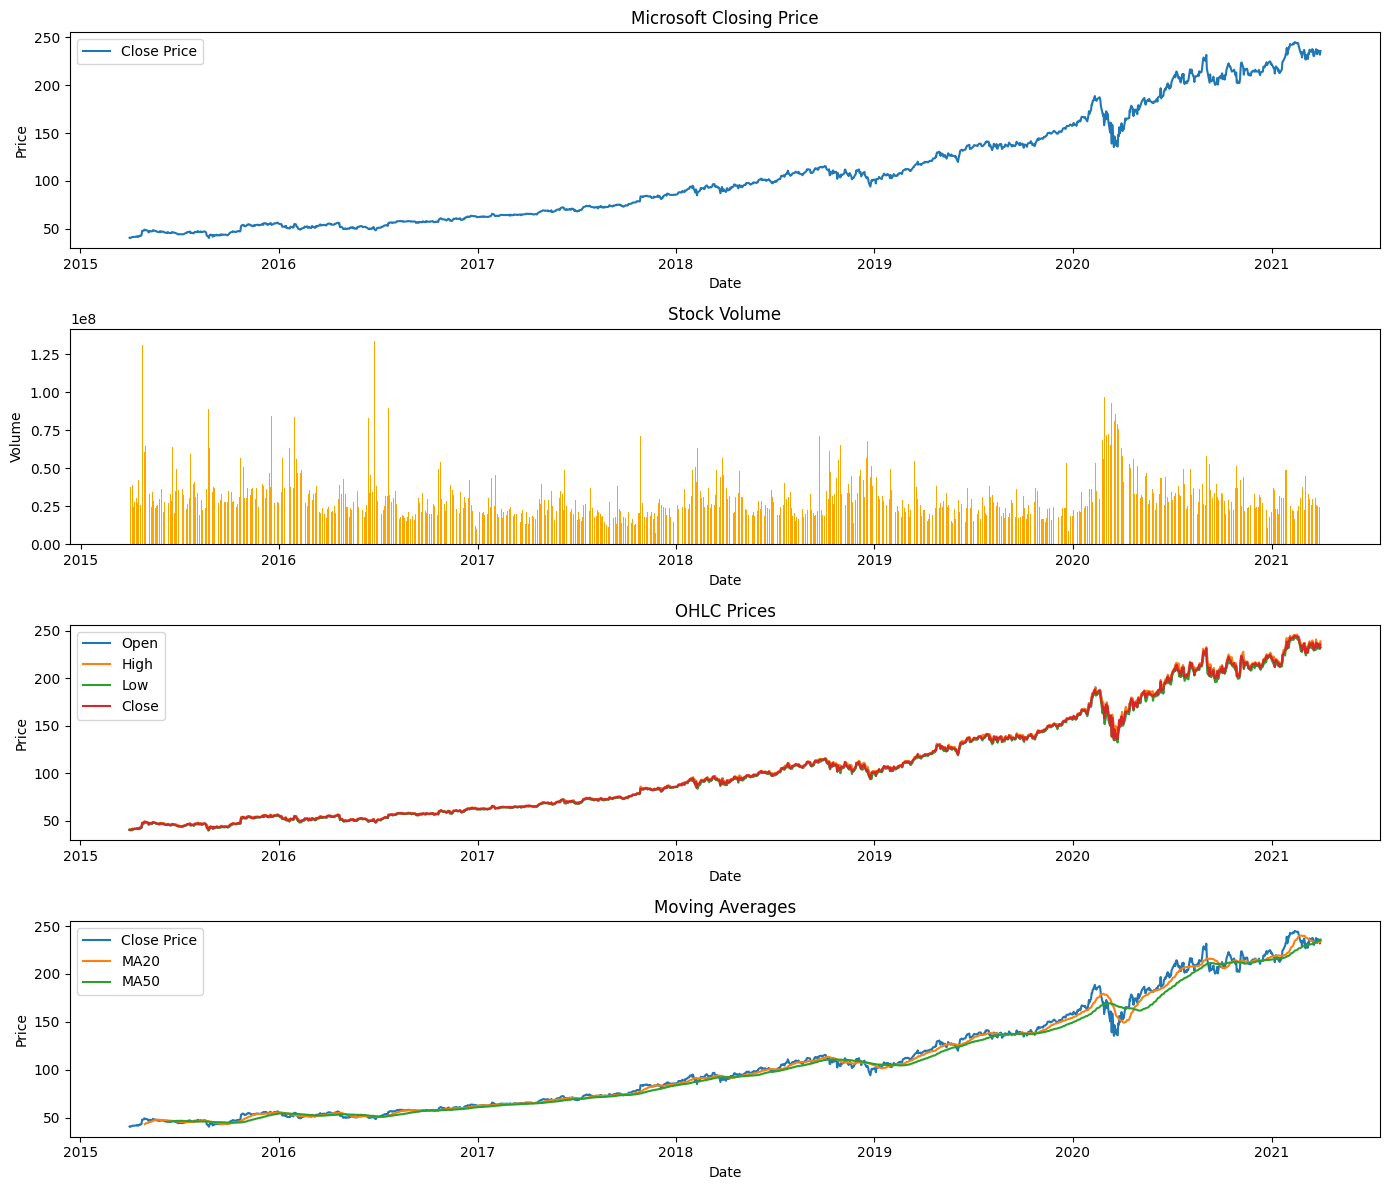

Baseline Model Summary:


Model: "functional_22"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_23      │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_74 (Dense)    │ (None, 30, 16)    │         32 │ input_layer_23[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 16)    │      2,160 │ dense_74[0][0],   │
│ (MultiHeadAttentio… │                   │            │ dense_74[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_54          │ (None, 30, 16)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_34 (Add)        │ (None, 30, 16)    │          0 │ dense_74[0][0],   │
│                     │                   │            │ dropout_54[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 16)    │         32 │ add_34[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_75 (Dense)    │ (None, 30, 64)    │      1,088 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_76 (Dense)    │ (None, 30, 16)    │      1,040 │ dense_75[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_55          │ (None, 30, 16)    │          0 │ dense_76[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_35 (Add)        │ (None, 30, 16)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_55[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 16)    │         32 │ add_35[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_12          │ (None, 480)       │          0 │ layer_normalizat… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_77 (Dense)    │ (None, 1)         │        481 │ flatten_12[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,865 (19.00 KB)

 Trainable params: 4,865 (19.00 KB)

 Non-trainable params: 0 (0.00 B)

Training baseline model...
Epoch 1/20
17/17 - 6s - 346ms/step - loss: 0.1588 - val_loss: 0.1748
Epoch 2/20
17/17 - 0s - 18ms/step - loss: 0.0667 - val_loss: 0.0386
Epoch 3/20
17/17 - 0s - 18ms/step - loss: 0.0459 - val_loss: 0.0558
Epoch 4/20
17/17 - 1s - 37ms/step - loss: 0.0299 - val_loss: 0.0689
Epoch 5/20
17/17 - 0s - 19ms/step - loss: 0.0240 - val_loss: 0.0475
Epoch 6/20
17/17 - 1s - 37ms/step - loss: 0.0198 - val_loss: 0.0300
Epoch 7/20
17/17 - 1s - 38ms/step - loss: 0.0130 - val_loss: 0.0327
Epoch 8/20
17/17 - 1s - 34ms/step - loss: 0.0103 - val_loss: 0.0328
Epoch 9/20
17/17 - 0s - 20ms/step - loss: 0.0080 - val_loss: 0.0264
Epoch 10/20
17/17 - 1s - 35ms/step - loss: 0.0067 - val_loss: 0.0320
Epoch 11/20
17/17 - 1s - 37ms/step - loss: 0.0060 - val_loss: 0.0263
Epoch 12/20
17/17 - 1s - 36ms/step - loss: 0.0041 - val_loss: 0.0279
Epoch 13/20
17/17 - 1s - 38ms/step - loss: 0.0039 - val_loss: 0.0234
Epoch 14/20
17/17 - 1s - 36ms/step - loss: 0.0042 - val_loss: 0.0272
Epoch 15/20
17/

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step

Baseline Model Performance Metrics:
MSE: 6617.839446
MAE: 80.049805
RMSE: 81.350104
R² Score: -26.527746

Starting Grid Search hyperparameter tuning...

Training model with tf_units=8, dropout_rate=0.1, learning_rate=0.001
Validation loss: 0.033411

Training model with tf_units=8, dropout_rate=0.1, learning_rate=0.0005
Validation loss: 0.047003

Training model with tf_units=8, dropout_rate=0.2, learning_rate=0.001
Validation loss: 0.027277

Training model with tf_units=8, dropout_rate=0.2, learning_rate=0.0005
Validation loss: 0.053305

Training model with tf_units=16, dropout_rate=0.1, learning_rate=0.001
Validation loss: 0.030331

Training model with tf_units=16, dropout_rate=0.1, learning_rate=0.0005
Validation loss: 0.026678

Training model with tf_units=16, dropout_rate=0.2, learning_rate=0.001
Validation loss: 0.025181

Training model with tf_units=16, dropout_rate=0.2, learning_rate=0.0005
Validation loss: 0.039656

Training model with tf_u

Validation loss: 0.027341

Best hyperparameters found: tf_units=32, dropout_rate=0.2, learning_rate=0.001 with val_loss=0.011492
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step

Best Model Performance Metrics:
MSE: 8046.073693
MAE: 88.530376
RMSE: 89.699909
R² Score: -32.468668

Best Model Parameters Summary:
Total params: 17921
Trainable params: 17921
Non-trainable params: 0


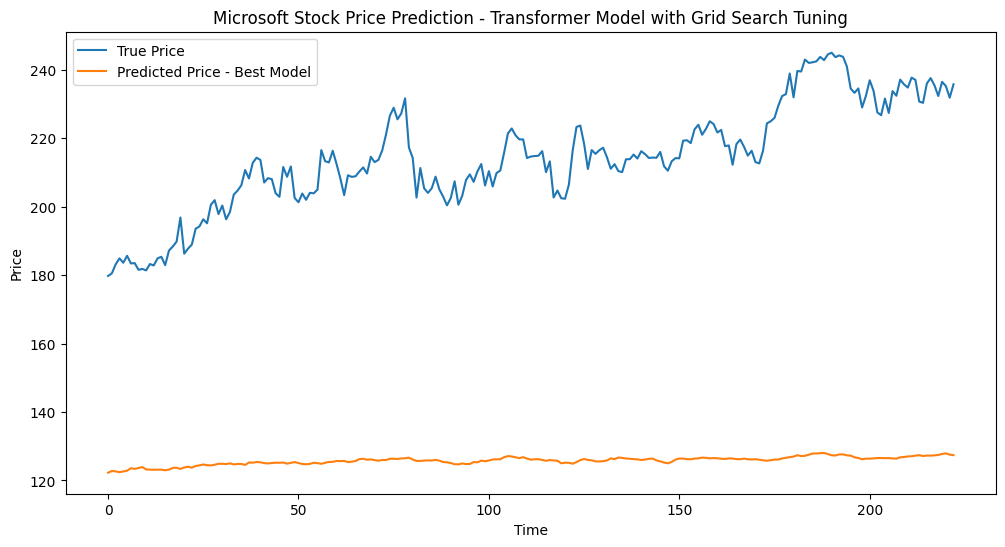

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

# --- TransformerStockPredictor class ---
class TransformerStockPredictor:
    def __init__(self, tf_units=16, dropout_rate=0.1, learning_rate=0.001, input_shape=(30,1)):
        self.tf_units = tf_units
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.input_shape = input_shape
        self.model = self.build_model()

    def build_model(self):
        inputs = layers.Input(shape=self.input_shape)

        x = layers.Dense(self.tf_units)(inputs)
        attn_output = layers.MultiHeadAttention(num_heads=2, key_dim=self.tf_units)(x, x)
        attn_output = layers.Dropout(self.dropout_rate)(attn_output)
        out1 = layers.LayerNormalization(epsilon=1e-6)(x + attn_output)

        ffn = layers.Dense(self.tf_units*4, activation='relu')(out1)
        ffn = layers.Dense(self.tf_units)(ffn)
        ffn_output = layers.Dropout(self.dropout_rate)(ffn)
        out2 = layers.LayerNormalization(epsilon=1e-6)(out1 + ffn_output)

        flat = layers.Flatten()(out2)
        outputs = layers.Dense(1)(flat)

        model = models.Model(inputs=inputs, outputs=outputs)
        model.compile(optimizer=optimizers.Adam(learning_rate=self.learning_rate),
                      loss='mse')
        return model

    def train(self, X_train, y_train, X_val, y_val, epochs=20, batch_size=32, verbose=0):
        history = self.model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            verbose=verbose
        )
        return history

    def evaluate(self, X_test, y_test):
        loss = self.model.evaluate(X_test, y_test, verbose=0)
        return loss

    def predict(self, X):
        return self.model.predict(X)

# --- Membuat dataset time series ---
def create_dataset(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    X = np.array(X)
    y = np.array(y)
    return X, y

# --- Load Data ---
file_path = os.path.join(path, "Microsoft_Stock.csv")
df = pd.read_csv(file_path, parse_dates=['Date'])
df.sort_values('Date', inplace=True)

# --- Grafik Microsoft Closing Price, Volume, OHLC dan Moving Averages ---
plt.figure(figsize=(14, 12))

# Closing Price
plt.subplot(4, 1, 1)
plt.plot(df['Date'], df['Close'], label='Close Price')
plt.title('Microsoft Closing Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Volume
plt.subplot(4, 1, 2)
plt.bar(df['Date'], df['Volume'], color='orange')
plt.title('Stock Volume')
plt.xlabel('Date')
plt.ylabel('Volume')

# OHLC
plt.subplot(4, 1, 3)
plt.plot(df['Date'], df['Open'], label='Open')
plt.plot(df['Date'], df['High'], label='High')
plt.plot(df['Date'], df['Low'], label='Low')
plt.plot(df['Date'], df['Close'], label='Close')
plt.title('OHLC Prices')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Moving Averages (20 and 50 days)
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA50'] = df['Close'].rolling(window=50).mean()

plt.subplot(4, 1, 4)
plt.plot(df['Date'], df['Close'], label='Close Price')
plt.plot(df['Date'], df['MA20'], label='MA20')
plt.plot(df['Date'], df['MA50'], label='MA50')
plt.title('Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

plt.tight_layout()
plt.show()

# --- Data Preparation for Model ---
prices = df['Close'].values.reshape(-1, 1)
scaler = MinMaxScaler()
prices_scaled = scaler.fit_transform(prices)
sequence_length = 30
X, y = create_dataset(prices_scaled, sequence_length)

total_samples = len(X)
train_end = int(total_samples * 0.7)
val_end = int(total_samples * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

input_shape = (sequence_length, 1)

# --- Baseline Model Training ---
baseline_model = TransformerStockPredictor(tf_units=16, dropout_rate=0.1, learning_rate=0.001, input_shape=input_shape)
print("Baseline Model Summary:")
baseline_model.model.summary()

print("Training baseline model...")
baseline_history = baseline_model.train(X_train, y_train, X_val, y_val, epochs=20, batch_size=64, verbose=2)

# --- Evaluate Baseline ---
y_pred_baseline = baseline_model.predict(X_test)
y_test_rescaled = scaler.inverse_transform(y_test)
y_pred_baseline_rescaled = scaler.inverse_transform(y_pred_baseline)

mse_baseline = mean_squared_error(y_test_rescaled, y_pred_baseline_rescaled)
mae_baseline = mean_absolute_error(y_test_rescaled, y_pred_baseline_rescaled)
rmse_baseline = np.sqrt(mse_baseline)
r2_baseline = r2_score(y_test_rescaled, y_pred_baseline_rescaled)

print("\nBaseline Model Performance Metrics:")
print(f"MSE: {mse_baseline:.6f}")
print(f"MAE: {mae_baseline:.6f}")
print(f"RMSE: {rmse_baseline:.6f}")
print(f"R² Score: {r2_baseline:.6f}")

# --- Grid Search Hyperparameter Tuning ---
print("\nStarting Grid Search hyperparameter tuning...")

tf_units_list = [8, 16, 32]
dropout_rates = [0.1, 0.2]
learning_rates = [0.001, 0.0005]

best_val_loss = float('inf')
best_params = None
best_model = None

for tf_units in tf_units_list:
    for dropout_rate in dropout_rates:
        for learning_rate in learning_rates:
            print(f"\nTraining model with tf_units={tf_units}, dropout_rate={dropout_rate}, learning_rate={learning_rate}")
            model = TransformerStockPredictor(tf_units=tf_units, dropout_rate=dropout_rate, learning_rate=learning_rate, input_shape=input_shape)
            history = model.train(X_train, y_train, X_val, y_val, epochs=20, batch_size=64, verbose=0)
            val_loss = min(history.history['val_loss'])
            print(f"Validation loss: {val_loss:.6f}")

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_params = (tf_units, dropout_rate, learning_rate)
                best_model = model

print(f"\nBest hyperparameters found: tf_units={best_params[0]}, dropout_rate={best_params[1]}, learning_rate={best_params[2]} with val_loss={best_val_loss:.6f}")

# --- Evaluate Best Model ---
y_pred_best = best_model.predict(X_test)
y_pred_best_rescaled = scaler.inverse_transform(y_pred_best)

mse_best = mean_squared_error(y_test_rescaled, y_pred_best_rescaled)
mae_best = mean_absolute_error(y_test_rescaled, y_pred_best_rescaled)
rmse_best = np.sqrt(mse_best)
r2_best = r2_score(y_test_rescaled, y_pred_best_rescaled)

print("\nBest Model Performance Metrics:")
print(f"MSE: {mse_best:.6f}")
print(f"MAE: {mae_best:.6f}")
print(f"RMSE: {rmse_best:.6f}")
print(f"R² Score: {r2_best:.6f}")

# --- Model Params Summary ---
total_params = best_model.model.count_params()
trainable_params = np.sum([tf.keras.backend.count_params(w) for w in best_model.model.trainable_weights])
non_trainable_params = total_params - trainable_params

print("\nBest Model Parameters Summary:")
print(f"Total params: {total_params}")
print(f"Trainable params: {trainable_params}")
print(f"Non-trainable params: {non_trainable_params}")

# --- Plot Prediksi Best Model ---
plt.figure(figsize=(12,6))
plt.plot(y_test_rescaled, label='True Price')
plt.plot(y_pred_best_rescaled, label='Predicted Price - Best Model')
plt.title('Microsoft Stock Price Prediction - Transformer Model with Grid Search Tuning')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()


##**Transformer S3 Baseline + Tuning + SMOTE**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.model_selection import train_test_split, ParameterGrid
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Download dataset Microsoft stock time series
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")
file_path = os.path.join(path, "Microsoft_Stock.csv")


Before SMOTE: class distribution = [477 559]
After SMOTE: class distribution = [559 559]
Starting Grid Search...
Testing parameters: {'batch_size': 32, 'dropout_rate': 0.1, 'epochs': 30, 'learning_rate': 0.001, 'tf_units': 16}
Epoch 1/30
35/35 - 5s - 134ms/step - accuracy: 0.4946 - loss: 0.7418 - val_accuracy: 0.4459 - val_loss: 0.7155
Epoch 2/30
35/35 - 0s - 11ms/step - accuracy: 0.5107 - loss: 0.7041 - val_accuracy: 0.4459 - val_loss: 0.7062
Epoch 3/30
35/35 - 0s - 12ms/step - accuracy: 0.5179 - loss: 0.7061 - val_accuracy: 0.4459 - val_loss: 0.7033
Epoch 4/30
35/35 - 1s - 17ms/step - accuracy: 0.5089 - loss: 0.7043 - val_accuracy: 0.4459 - val_loss: 0.7058
Epoch 5/30
35/35 - 0s - 12ms/step - accuracy: 0.5116 - loss: 0.7024 - val_accuracy: 0.4459 - val_loss: 0.7053
Epoch 6/30
35/35 - 0s - 11ms/step - accuracy: 0.5107 - loss: 0.6994 - val_accuracy: 0.4459 - val_loss: 0.7020
Epoch 7/30
35/35 - 1s - 18ms/step - accuracy: 0.5081 - loss: 0.7029 - val_accuracy: 0.4459 - val_loss: 0.7022
Ep

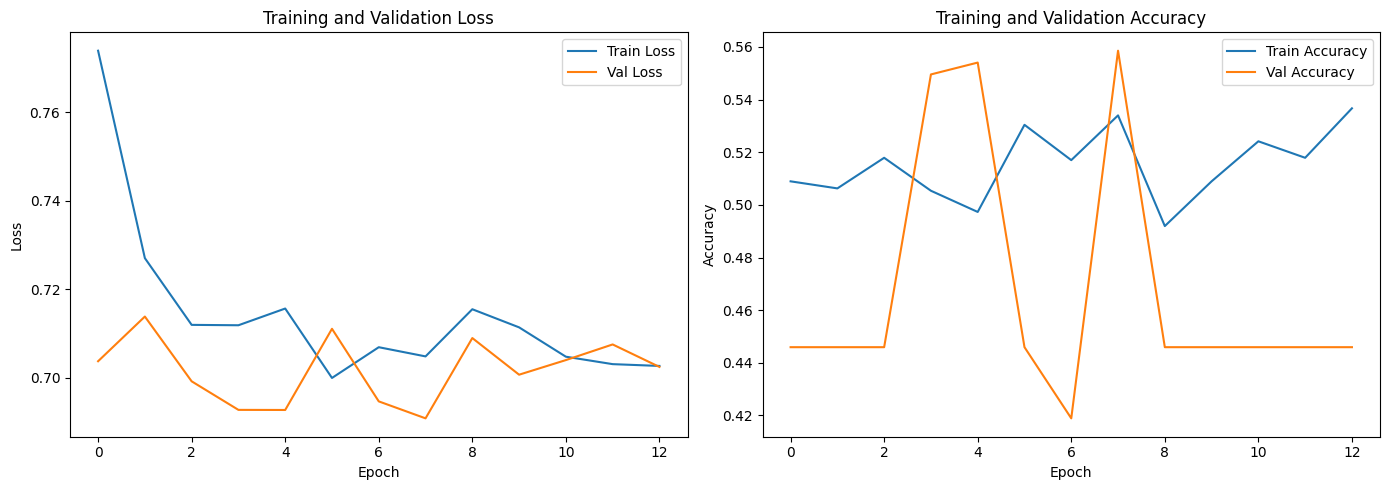

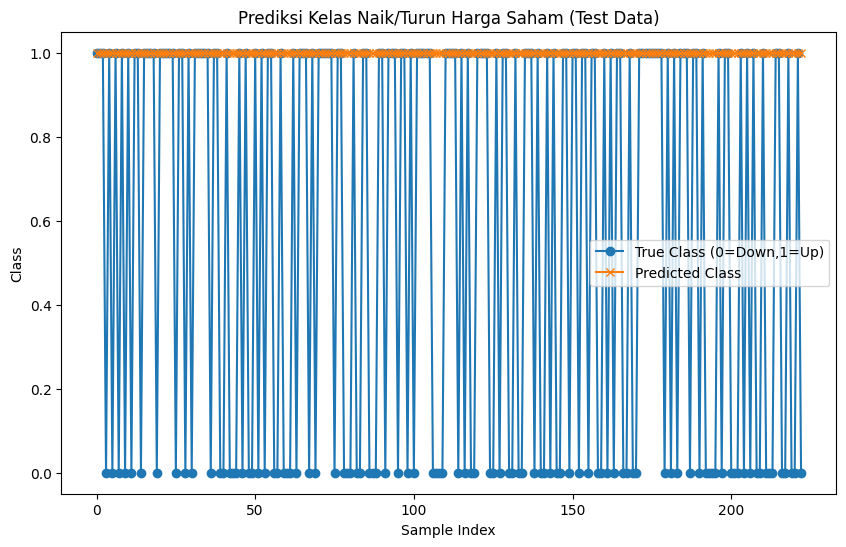

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 

Best Model Performance Metrics (Regresi Probabilitas):
MSE: 0.2482
MAE: 0.4976
RMSE: 0.4982
R² Score: -0.0054


In [ ]:
# --- Transformer Model untuk Klasifikasi ---
class TransformerStockClassifier:
    def __init__(self, tf_units=16, dropout_rate=0.1, learning_rate=0.001, input_shape=(30,1)):
        self.tf_units = tf_units
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.input_shape = input_shape
        self.model = self.build_model()

    def build_model(self):
        inputs = layers.Input(shape=self.input_shape)

        x = layers.Dense(self.tf_units)(inputs)
        attn_output = layers.MultiHeadAttention(num_heads=2, key_dim=self.tf_units)(x, x)
        attn_output = layers.Dropout(self.dropout_rate)(attn_output)
        out1 = layers.LayerNormalization(epsilon=1e-6)(x + attn_output)

        ffn = layers.Dense(self.tf_units*4, activation='relu')(out1)
        ffn = layers.Dense(self.tf_units)(ffn)
        ffn_output = layers.Dropout(self.dropout_rate)(ffn)
        out2 = layers.LayerNormalization(epsilon=1e-6)(out1 + ffn_output)

        flat = layers.Flatten()(out2)
        outputs = layers.Dense(1, activation='sigmoid')(flat)  # Klasifikasi biner

        model = models.Model(inputs=inputs, outputs=outputs)
        model.compile(optimizer=optimizers.Adam(learning_rate=self.learning_rate),
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    def train(self, X_train, y_train, X_val, y_val, epochs=20, batch_size=32):
        early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        history = self.model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            verbose=2,
            callbacks=[early_stop]
        )
        return history

    def evaluate(self, X_test, y_test):
        loss, accuracy = self.model.evaluate(X_test, y_test, verbose=0)
        return loss, accuracy

    def predict(self, X):
        preds = self.model.predict(X)
        return (preds > 0.5).astype(int).flatten()


# --- Fungsi Membuat Dataset Sequence ---
def create_dataset(data, labels, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(labels[i+seq_length])
    return np.array(X), np.array(y)


# --- Load Data ---
file_path = os.path.join(path, "Microsoft_Stock.csv")
df = pd.read_csv(file_path, parse_dates=['Date'])
df.sort_values('Date', inplace=True)

# --- Label Klasifikasi Naik/Turun ---
# Naik (1) jika harga tutup hari ini > harga tutup hari sebelumnya, turun (0) jika sebaliknya
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)
df.dropna(subset=['Target'], inplace=True)

# --- Normalisasi Harga Close ---
prices = df['Close'].values.reshape(-1,1)
scaler = MinMaxScaler()
prices_scaled = scaler.fit_transform(prices)

# --- Buat Dataset sequence dengan sliding window ---
sequence_length = 30
X_all, y_all = create_dataset(prices_scaled, df['Target'].values, sequence_length)

# --- Split Data: Train=70%, Val=15%, Test=15% ---
total_samples = len(X_all)
train_end = int(total_samples * 0.7)
val_end = int(total_samples * 0.85)

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val, y_val = X_all[train_end:val_end], y_all[train_end:val_end]
X_test, y_test = X_all[val_end:], y_all[val_end:]

# --- Terapkan SMOTE pada data training ---
# Flatten data karena SMOTE butuh 2D input
nsamples, nx, ny = X_train.shape
X_train_reshaped = X_train.reshape((nsamples, nx*ny))

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_reshaped, y_train)

# Kembalikan ke bentuk 3D untuk model
X_train_res = X_train_res.reshape((-1, nx, ny))

print(f"Before SMOTE: class distribution = {np.bincount(y_train)}")
print(f"After SMOTE: class distribution = {np.bincount(y_train_res)}")

input_shape = (sequence_length, 1)

# --- Grid Search Parameter Tuning ---
param_grid = {
    'tf_units': [16, 32],
    'dropout_rate': [0.1, 0.2],
    'learning_rate': [0.001, 0.0005],
    'batch_size': [32, 64],
    'epochs': [30]
}

best_f1 = 0
best_params = None
best_model = None
best_history = None

print("Starting Grid Search...")

for params in ParameterGrid(param_grid):
    print(f"Testing parameters: {params}")
    model = TransformerStockClassifier(
        tf_units=params['tf_units'],
        dropout_rate=params['dropout_rate'],
        learning_rate=params['learning_rate'],
        input_shape=input_shape
    )
    history = model.train(
        X_train_res, y_train_res, X_val, y_val,
        epochs=params['epochs'],
        batch_size=params['batch_size']
    )
    y_val_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_val_pred)
    print(f"Validation F1 Score: {f1:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        best_params = params
        best_model = model
        best_history = history

print(f"\nBest params: {best_params}")
print(f"Best validation F1 score: {best_f1:.4f}")

# --- Evaluasi model terbaik pada test data ---
y_test_pred = best_model.predict(X_test)

acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print("\nTest Performance Metrics:")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1 Score: {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# --- Grafik Loss dan Accuracy Saat Training ---
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(best_history.history['loss'], label='Train Loss')
plt.plot(best_history.history['val_loss'], label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(best_history.history['accuracy'], label='Train Accuracy')
plt.plot(best_history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# --- Grafik Prediksi vs Aktual (Test Data) ---
plt.figure(figsize=(10,6))
plt.plot(y_test, label='True Class (0=Down,1=Up)', marker='o')
plt.plot(y_test_pred, label='Predicted Class', marker='x')
plt.title('Prediksi Kelas Naik/Turun Harga Saham (Test Data)')
plt.xlabel('Sample Index')
plt.ylabel('Class')
plt.legend()
plt.show()

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Setelah prediksi kelas
y_test_pred_proba = best_model.model.predict(X_test).flatten()  # Probabilitas output sigmoid

# Hitung metrik regresi MSE, MAE, RMSE, dan R2 Score menggunakan probabilitas prediksi
mse = mean_squared_error(y_test, y_test_pred_proba)
mae = mean_absolute_error(y_test, y_test_pred_proba)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred_proba)

print("\nBest Model Performance Metrics (Regresi Probabilitas):")
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")


##**Transformer S4 Badeline + Tuning + SMOTE + Attention**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterGrid
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks

In [ ]:
# Download dataset Microsoft stock time series
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")
file_path = os.path.join(path, "Microsoft_Stock.csv")

Before SMOTE: class distribution = [477 559]
After SMOTE: class distribution = [559 559]
Starting Grid Search for Skenario 4 with extra Attention...
Testing parameters: {'batch_size': 32, 'dropout_rate': 0.1, 'epochs': 30, 'learning_rate': 0.001, 'tf_units': 16}
Epoch 1/30
35/35 - 7s - 210ms/step - accuracy: 0.4902 - loss: 0.7328 - val_accuracy: 0.4459 - val_loss: 0.7236
Epoch 2/30
35/35 - 1s - 21ms/step - accuracy: 0.5376 - loss: 0.7039 - val_accuracy: 0.4459 - val_loss: 0.7040
Epoch 3/30
35/35 - 1s - 37ms/step - accuracy: 0.5134 - loss: 0.7040 - val_accuracy: 0.4459 - val_loss: 0.6988
Epoch 4/30
35/35 - 1s - 40ms/step - accuracy: 0.4955 - loss: 0.7103 - val_accuracy: 0.4459 - val_loss: 0.7010
Epoch 5/30
35/35 - 1s - 32ms/step - accuracy: 0.5313 - loss: 0.6979 - val_accuracy: 0.4459 - val_loss: 0.7079
Epoch 6/30
35/35 - 1s - 31ms/step - accuracy: 0.5143 - loss: 0.7018 - val_accuracy: 0.4459 - val_loss: 0.7034
Epoch 7/30
35/35 - 1s - 18ms/step - accuracy: 0.5233 - loss: 0.6962 - val_ac

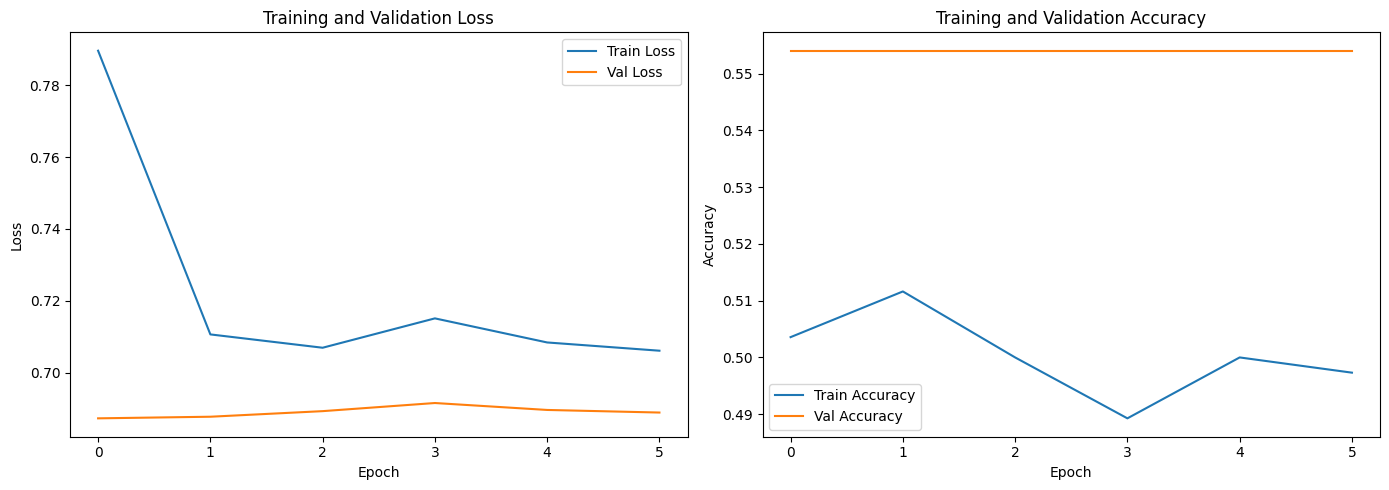

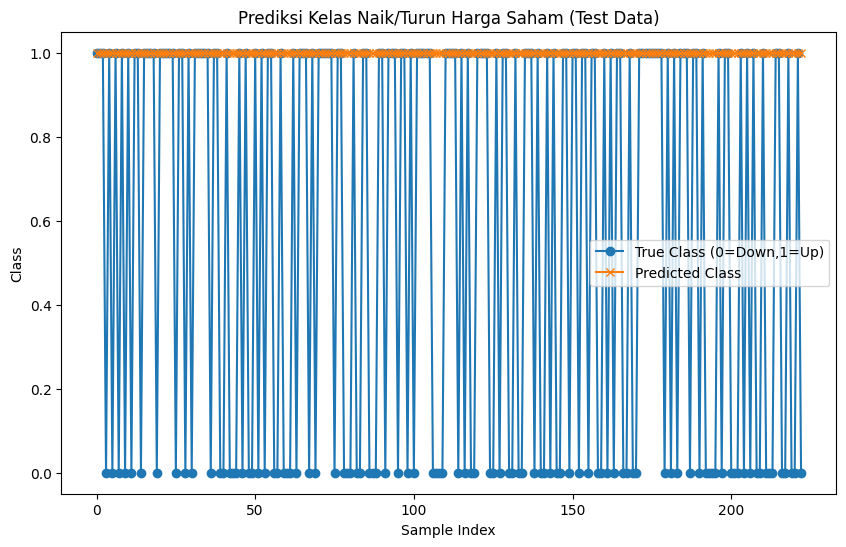

In [ ]:


# --- Transformer dengan Attention Ekspisit Patch untuk Skenario 4 ---
class TransformerStockClassifierWithAttention:
    def __init__(self, tf_units=32, dropout_rate=0.1, learning_rate=0.001, input_shape=(30,1)):
        self.tf_units = tf_units
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.input_shape = input_shape
        self.model = self.build_model()

    def build_model(self):
        inputs = layers.Input(shape=self.input_shape)  # (batch, seq_len, features)

        # Embedding / dense transform awal ke tf_units dimensi
        x = layers.Dense(self.tf_units)(inputs)  # (batch, seq_len, tf_units)

        # Multi-Head Attention Layer (query, key, value = x)
        attn_output = layers.MultiHeadAttention(num_heads=4, key_dim=self.tf_units)(x, x)
        attn_output = layers.Dropout(self.dropout_rate)(attn_output)
        out1 = layers.LayerNormalization(epsilon=1e-6)(x + attn_output)  # Residual connection

        # Feed Forward Network (FFN)
        ffn = layers.Dense(self.tf_units * 4, activation='relu')(out1)
        ffn = layers.Dense(self.tf_units)(ffn)
        ffn_output = layers.Dropout(self.dropout_rate)(ffn)
        out2 = layers.LayerNormalization(epsilon=1e-6)(out1 + ffn_output)  # Residual

        # Additional Attention Layer to capture complex relations
        extra_attn = layers.MultiHeadAttention(num_heads=2, key_dim=self.tf_units)(out2, out2)
        extra_attn = layers.Dropout(self.dropout_rate)(extra_attn)
        out3 = layers.LayerNormalization(epsilon=1e-6)(out2 + extra_attn)  # Residual

        # Flatten and output layer klasifikasi biner (sigmoid)
        flat = layers.Flatten()(out3)
        outputs = layers.Dense(1, activation='sigmoid')(flat)

        model = models.Model(inputs=inputs, outputs=outputs)
        model.compile(
            optimizer=optimizers.Adam(learning_rate=self.learning_rate),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )
        return model

    def train(self, X_train, y_train, X_val, y_val, epochs=30, batch_size=32):
        early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        history = self.model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            verbose=2,
            callbacks=[early_stop]
        )
        return history

    def evaluate(self, X_test, y_test):
        loss, accuracy = self.model.evaluate(X_test, y_test, verbose=0)
        return loss, accuracy

    def predict(self, X):
        preds = self.model.predict(X)
        return (preds > 0.5).astype(int).flatten()

# --- Dataset sequence function sama seperti sebelumnya ---
def create_dataset(data, labels, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(labels[i+seq_length])
    return np.array(X), np.array(y)

# --- Load dan persiapkan data ---
path = kagglehub.dataset_download("vijayvvenkitesh/microsoft-stock-time-series-analysis")
file_path = os.path.join(path, "Microsoft_Stock.csv")
df = pd.read_csv(file_path, parse_dates=['Date'])
df.sort_values('Date', inplace=True)

# Label Klasifikasi Naik (1) / Turun (0)
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)
df.dropna(subset=['Target'], inplace=True)

# Normalisasi harga close
prices = df['Close'].values.reshape(-1,1)
scaler = MinMaxScaler()
prices_scaled = scaler.fit_transform(prices)

sequence_length = 30
X_all, y_all = create_dataset(prices_scaled, df['Target'].values, sequence_length)

# Split data train:val:test = 70%:15%:15%
total_samples = len(X_all)
train_end = int(total_samples*0.7)
val_end = int(total_samples*0.85)

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val, y_val = X_all[train_end:val_end], y_all[train_end:val_end]
X_test, y_test = X_all[val_end:], y_all[val_end:]

# Terapkan SMOTE pada data train, reshape ke 2D dulu
nsamples, nx, ny = X_train.shape
X_train_reshaped = X_train.reshape((nsamples, nx*ny))

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_reshaped, y_train)

# Kembalikan bentuk 3D ke input shape Model
X_train_res = X_train_res.reshape((-1, nx, ny))

print(f"Before SMOTE: class distribution = {np.bincount(y_train)}")
print(f"After SMOTE: class distribution = {np.bincount(y_train_res)}")

input_shape = (sequence_length, 1)

# --- Grid Search hyperparameter tuning ---
param_grid = {
    'tf_units': [16, 32],
    'dropout_rate': [0.1, 0.2],
    'learning_rate': [0.001, 0.0005],
    'batch_size': [32, 64],
    'epochs': [30]
}

best_f1 = 0
best_params = None
best_model = None
best_history = None

print("Starting Grid Search for Skenario 4 with extra Attention...")

for params in ParameterGrid(param_grid):
    print(f"Testing parameters: {params}")
    model = TransformerStockClassifierWithAttention(
        tf_units=params['tf_units'],
        dropout_rate=params['dropout_rate'],
        learning_rate=params['learning_rate'],
        input_shape=input_shape
    )
    history = model.train(
        X_train_res, y_train_res, X_val, y_val,
        epochs=params['epochs'],
        batch_size=params['batch_size']
    )
    y_val_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_val_pred)
    print(f"Validation F1 Score: {f1:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        best_params = params
        best_model = model
        best_history = history

print(f"\nBest params: {best_params}")
print(f"Best validation F1 score: {best_f1:.4f}")

# --- Evaluasi final terbaik pada test data ---
y_test_pred = best_model.predict(X_test)
y_test_pred_proba = best_model.model.predict(X_test).flatten()

acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred_proba)
mae = mean_absolute_error(y_test, y_test_pred_proba)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred_proba)

print("\nTest Performance Metrics (Classification):")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nBest Model Performance Metrics (Regression on Probabilities):")
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# --- Visualisasi grafik training loss & accuracy ---
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(best_history.history['loss'], label='Train Loss')
plt.plot(best_history.history['val_loss'], label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(best_history.history['accuracy'], label='Train Accuracy')
plt.plot(best_history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# --- Visualisasi Prediksi vs Aktual (Test Data) ---
plt.figure(figsize=(10,6))
plt.plot(y_test, label='True Class (0=Down,1=Up)', marker='o')
plt.plot(y_test_pred, label='Predicted Class', marker='x')
plt.title('Prediksi Kelas Naik/Turun Harga Saham (Test Data)')
plt.xlabel('Sample Index')
plt.ylabel('Class')
plt.legend()
plt.show()
